In [11]:
cd ./wrkDir/s18-2/

[Errno 2] No such file or directory: './wrkDir/s18-2/'
/work/xiangchong.li/work/S18ASimHSC/s18-2


In [12]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import scipy.optimize as opt
import sim_analysis_utilities as utilities

import matplotlib
from matplotlib.ticker import ScalarFormatter
formatter = ScalarFormatter()
formatter.set_scientific(False)
import matplotlib.pyplot as plt
cm  = plt.cm.get_cmap('RdYlBu')

import logging
logging.basicConfig(filename='4-ReGaus_Calib.log',level=logging.INFO)

anaDir='./anaCat'
pltDir='./plot/reGausCalib/'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

# Blinding parameters
add_m_val=0.
add_a_val=0.

# Whether to remove selection bias
force_90_pair=True

ngal_bin=20*100*100
nbin_1d=8
dshape =   (nbin_1d,nbin_1d)
    

Populating the interactive namespace from numpy and matplotlib


In [13]:
# Read catalog
dataF =   pd.read_hdf(inFname,mode='r')
dataF =   dataF[dataF['wlmask_90rot']]
data  =   dataF.to_records(index=True)
if force_90_pair:
    assert np.all(data[0::2]['ipos']==(data['ipos'][1::2]-1))
    assert np.all(data[0::2]['weight']==(data['weight'][1::2]))

# Weight Bias
Here we do not force the orthorgonal galaxies pairs to have the same weights and estimate the additional multiplicative bias and additive bias.

## Sampling Weight Bias

In [14]:
prefix='weightBias'
# Load outcomes of reGaus_shearCalib.py
shearBinName=   os.path.join(pltDir,'shear_slide_bins.npy')
outcomes=np.load(shearBinName)

nsim   =   len(outcomes)
psf_e1 =   np.zeros(nsim)
psf_e2 =   np.zeros(nsim)
weight =   np.zeros(nsim)
g1_true=   np.zeros(nsim)
g2_true=   np.zeros(nsim)
g1_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
g2_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
sigma_g_bins=   np.zeros((nbin_1d,nbin_1d,nsim))
dshape =   (nbin_1d,nbin_1d)

for iout,outcome in enumerate(outcomes):
    g1_true[iout]  =   outcome[0]
    g2_true[iout]  =   outcome[1]
    g1_bins[:,:,iout]  =   outcome[2]
    g2_bins[:,:,iout]  =   outcome[3]
    sigma_g_bins[:,:,iout]  =   outcome[4]
    psf_e1[iout]  =   outcome[5]
    psf_e2[iout]  =   outcome[6]
    weight[iout]  =   outcome[7]

m1_bins    =   np.zeros(dshape)
a1_bins    =   np.zeros(dshape)
sigm1_bins =   np.zeros(dshape)
siga1_bins =   np.zeros(dshape)

# For each of the sliding bins in SNR/resolution.
for j in range(nbin_1d):
    for k in range(nbin_1d):
        # divide sigma by sqrt(N)
        sigma_vals = sigma_g_bins[j,k,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+5)
        # get multiplicative bias and additive bias
        m1_bins[j,k],a1_bins[j,k], \
        sigm1_bins[j,k],siga1_bins[j,k]= \
            utilities.get_m_c_a(g1_bins[j,k,tmp_use],
                                g2_bins[j,k,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
        logging.info('Bin %d %d bias analysis:'%(j,k))
        logging.info('m = %.3f +/- %.3f' % (m1_bins[j,k], sigm1_bins[j,k]))
        logging.info('a = %.3f +/- %.3f' % (a1_bins[j,k], siga1_bins[j,k]))
        
shearName   =   os.path.join(pltDir,'shear_m_a_2d.csv')
shearTab    =   pd.read_csv(shearName).to_records()
m1_bins-= np.array(shearTab['m']).reshape(dshape)
a1_bins-= np.array(shearTab['a']).reshape(dshape)

snr_bins=shearTab['snr'].reshape(dshape)
res_bins=shearTab['res'].reshape(dshape)
fake_x=np.vstack((snr_bins.flatten(),res_bins.flatten()))
#Write data
out_data    =   list(zip(snr_bins.flatten(), res_bins.flatten(),
        m1_bins.flatten(), sigm1_bins.flatten(),
        a1_bins.flatten(), siga1_bins.flatten()))

biasBinFname=   os.path.join(pltDir,'%s_m_a_2d.csv' %(prefix))
mcBinTab    =   pd.DataFrame(data=out_data,columns=('snr','res','m','mSigma','a','aSigma'))
mcBinTab.to_csv(biasBinFname)

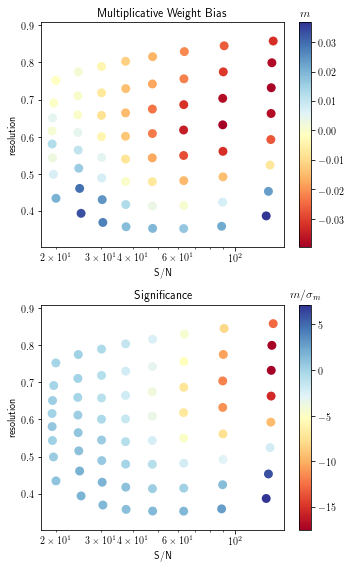

In [15]:
# Plot multiplicative bias in each bins
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m1_bins+add_m_val, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
if add_m_val > 0:
    cbar.ax.set_title(r'$m+$constant')
else:
    cbar.ax.set_title(r'$m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Multiplicative Weight Bias')
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=m1_bins/sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m/\sigma_m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance')
plt.tight_layout()
#plt.savefig(pltDir+'%s_m_2d.png'%(prefix))

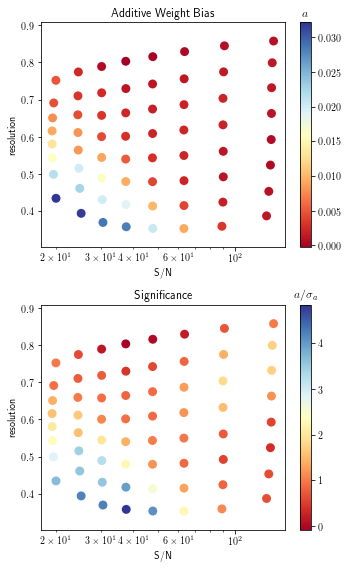

In [16]:
# Plot additive bias in each bin
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
fig = plt.figure(figsize=(5,8))
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=a1_bins+add_a_val, cmap=cm,vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Additive Weight Bias')
if add_a_val > 0:
    cbar.ax.set_title(r'$m+$constant')
else:
    cbar.ax.set_title(r'$a$' )
# Also plot errors in this case.
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins, c=a1_bins/siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a/\sigma_a$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance')
plt.tight_layout()
#plt.savefig(pltDir+'%s_a_2d.png'%(prefix))

## Modelling Weight Bias

In [17]:
# Fitting
outMA   =   {}

# Model fitting for multiplicative bias
m_opt, m_cov = opt.curve_fit(
    utilities.mwt_func, fake_x, m1_bins.flatten(), sigma=sigm1_bins.flatten(),
    bounds=([-np.inf,0.,0.,-np.inf],[0.,np.inf,np.inf,0.]))

outMA.update({'m_opt':m_opt,'m_cov':m_cov})
if True:
    print('m_wt model:')
    print('m=b+(c+(snr/20)**e)/(res+d)')
    for ind in range(len(m_opt)):
        print('%f +/- %f'%(m_opt[ind],m_cov[ind,ind]))

# For additive bias
a_opt, a_cov = opt.curve_fit(
    utilities.a_func, fake_x, a1_bins.flatten(), sigma=siga1_bins.flatten(),
    bounds=([-np.inf,-np.inf,-np.inf],[np.inf,np.inf,0.]))

outMA.update({'a_opt':a_opt,'a_cov':a_cov})

if True:
    print('a_wt model:')
    print('a=b*(res-c)*(snr/20)^d')
    for ind in range(len(a_opt)):
        print('%f +/- %f'%(a_opt[ind],a_cov[ind,ind]))

# Save results
maFname  =   os.path.join(pltDir,'%s_m_a_model_par.npy'%(prefix))
np.save(maFname,outMA)

m_wt model:
m=b+(c+(snr/20)**e)/(res+d)
-0.314170 +/- 0.551658
0.000000 +/- 24.072732
2.589814 +/- 65.384770
-0.035622 +/- 0.008671
a_wt model:
a=b*(res-c)*(snr/20)^d
-0.081363 +/- 0.000101
0.785924 +/- 0.000366
-1.492593 +/- 0.018340


Text(0.5, 1.0, 'Modelled Multiplicative Bias')

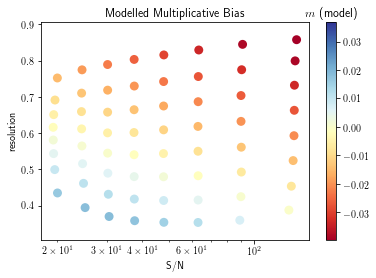

In [18]:
# Plot multiplicative bias model
m_vmin = np.min(m1_bins+add_m_val)
m_vmax = np.max(m1_bins+add_m_val)
a_vmin = np.min(a1_bins+add_a_val)
a_vmax = np.max(a1_bins+add_a_val)
m_opt   =   outMA['m_opt']
a_opt   =   outMA['a_opt']
# plot the model, residuals, and their significance
m_model =   utilities.mwt_func(fake_x, *m_opt).reshape(dshape)


fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=m_model, cmap=cm,
            vmin=m_vmin, vmax=m_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ (model)')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Modelled Multiplicative Bias')
#plt.savefig(pltDir+'%s_m_model_2d.png'%(prefix))

Text(0.5, 1.0, 'Modelled Additive Bias')

<Figure size 432x288 with 0 Axes>

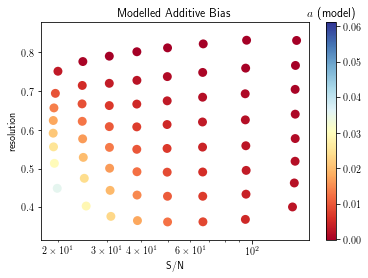

In [16]:
fig = plt.figure()
# Plot additive bias model
a_model = utilities.a_func(fake_x, *a_opt).reshape(nbin_1d, nbin_1d)
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(snr_bins, res_bins, c=a_model, cmap=cm,
            vmin=a_vmin, vmax=a_vmax, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ (model)')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Modelled Additive Bias')

#plt.savefig(pltDir+'%s_a_model_2d.png'%(prefix))

## Model Residuals for weight bias

In [21]:
# Record the mean dm dc for each bin
df_x=np.vstack((data['snr'],data['res']))
model_m =   utilities.mwt_func(df_x,*m_opt)
model_a =   utilities.a_func(df_x,*a_opt)
shape_weight = utilities.get_weight_model(data)*data['weight']

m_mres_bins = np.zeros((nbin_1d, nbin_1d))
a_mres_bins = np.zeros((nbin_1d, nbin_1d))
for j in range(nbin_1d):
    for k in range(nbin_1d):
        mask=(np.int_(data['calib_slide_ibins'])==j*nbin_1d+k)
        sum_weight=np.sum(shape_weight[mask])
        sum_m=np.sum(model_m[mask]*shape_weight[mask])
        sum_a=np.sum(model_a[mask]*shape_weight[mask])
        m_mres_bins[j,k] =sum_m/sum_weight
        a_mres_bins[j,k] =sum_a/sum_weight
m_mres_bins=m1_bins-m_mres_bins
a_mres_bins=a1_bins-a_mres_bins

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:15: RuntimeWarning: invalid value encountered in double_scalars
  from ipykernel import kernelapp as app
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in double_scalars
  app.launch_new_instance()


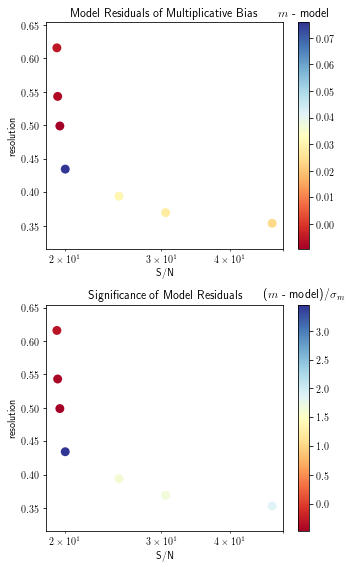

In [22]:
fig = plt.figure(figsize=(5,8))

# Plot residuals
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=m_mres_bins,
            cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$m$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Model Residuals of Multiplicative Bias ')

# Plot significance
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins,
            c=m_mres_bins/sigm1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($m$ - model)/$\sigma_m$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance of Model Residuals')
plt.tight_layout()
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

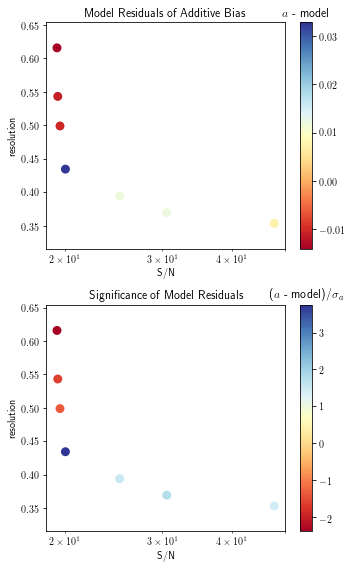

In [23]:
fig = plt.figure(figsize=(5,8))

# Plot residuals
ax = fig.add_subplot(211)
sc = ax.scatter(snr_bins, res_bins, c=a_mres_bins,
            cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'$a$ - model')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Model Residuals of Additive Bias ')

# Plot significance
ax = fig.add_subplot(212)
sc = ax.scatter(snr_bins, res_bins,
            c=a_mres_bins/siga1_bins, cmap=cm, s=80, edgecolors='none')
cbar = plt.colorbar(sc)
cbar.ax.set_title(r'($a$ - model)/$\sigma_a$')
plt.xscale('log')
plt.xlabel('S/N')
plt.ylabel('resolution')
plt.title('Significance of Model Residuals')
plt.tight_layout()
#plt.savefig(pltDir+'%s_Delta_m_model_2d.png'%(prefix))

In [24]:
# Write /delta m /delta a to csv file 
out_data=list(zip(snr_bins.flatten(), res_bins.flatten(),
        m_mres_bins.flatten(), sigm1_bins.flatten(),
        a_mres_bins.flatten(), siga1_bins.flatten()))
mcDeltaBinTab    =   pd.DataFrame(data=out_data,columns=('snr','res','dm','mSigma','da','aSigma'))
mcDeltaBinTab.to_csv(pltDir+'%s_dm_da_2d.csv'%(prefix))

# Simple Sanity Tests

In [25]:
test_weight_bias=True
indexList=  dataF.index.levels[1]
outData=[]
for index in indexList:
    catalog =   dataF.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    if not test_weight_bias:
        shape_weights[1::2] = shape_weights[0::2]
        e_rms[1::2] = e_rms[0::2]
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    if True:
        model_m = utilities.get_m_model(catalog,weight_bias=test_weight_bias)
        model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=test_weight_bias)
    if False:
        model_m = m1_bins.flatten()[np.int_(catalog['calib_slide_ibins'])]
        model_a=  a1_bins.flatten()[np.int_(catalog['calib_slide_ibins'])]
        model_c1= model_a*psf_e1
        model_c2= model_a*psf_e2
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)

In [27]:
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+10)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= 
    utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0056 +/- 0.0021
a = -0.0025 +/- 0.0008
